In [56]:
import pandas as pd


In [57]:
df = pd.read_csv('/content/credit_risk_dataset.csv')

In [58]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [60]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [61]:
df.shape

(32581, 12)

In [62]:
df['loan_status'].unique()
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

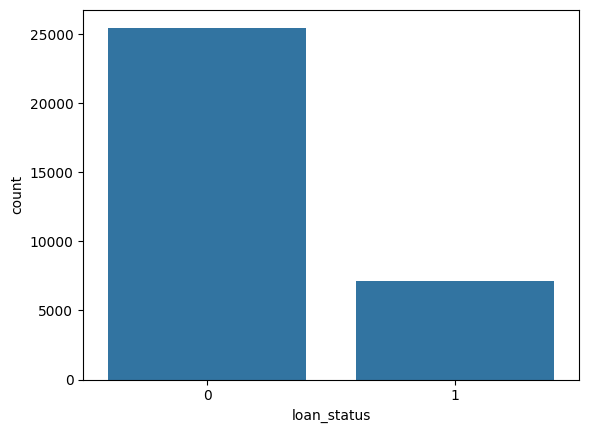

In [63]:
import seaborn as sns

sns.countplot(x='loan_status',data=df)

In [64]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [65]:
num_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

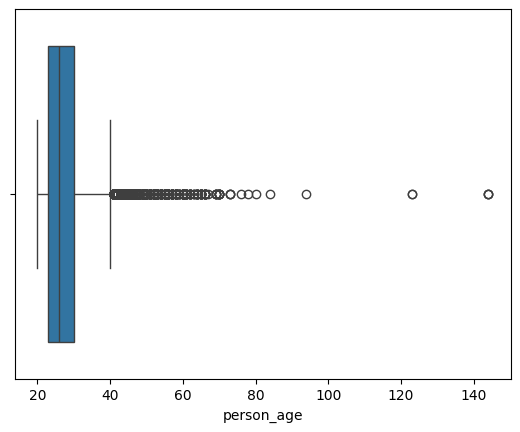

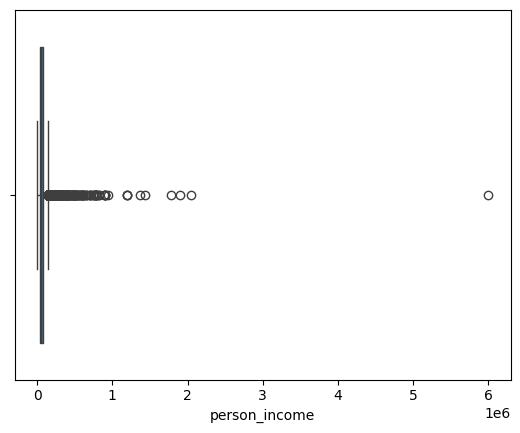

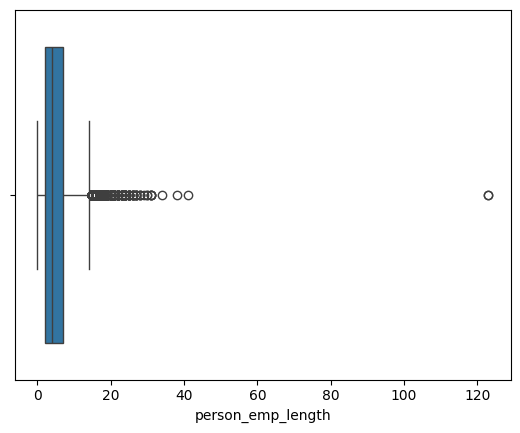

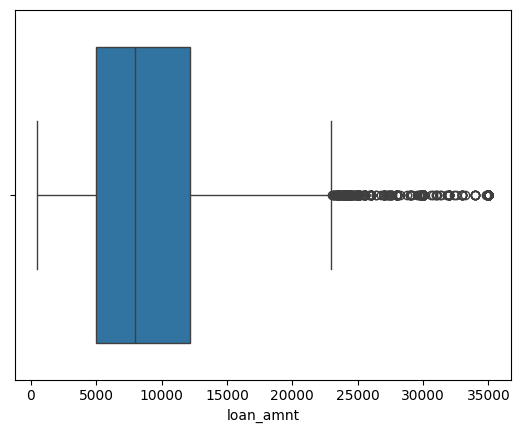

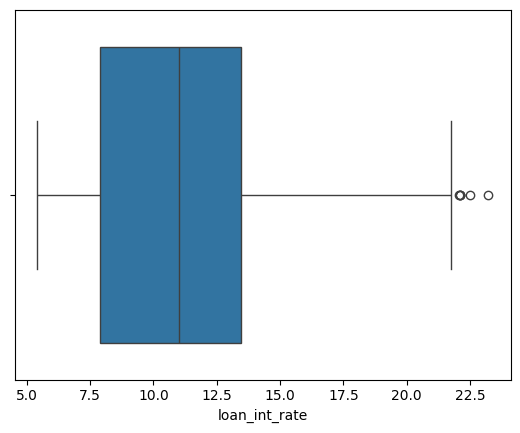

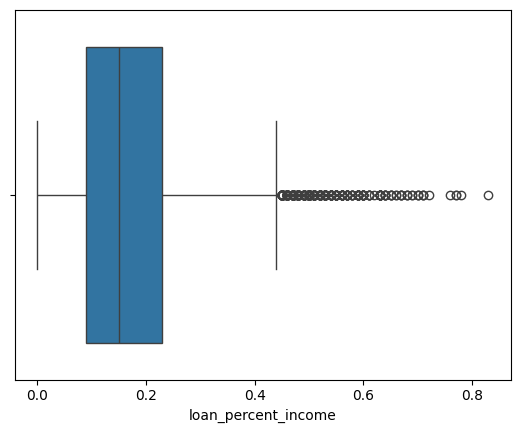

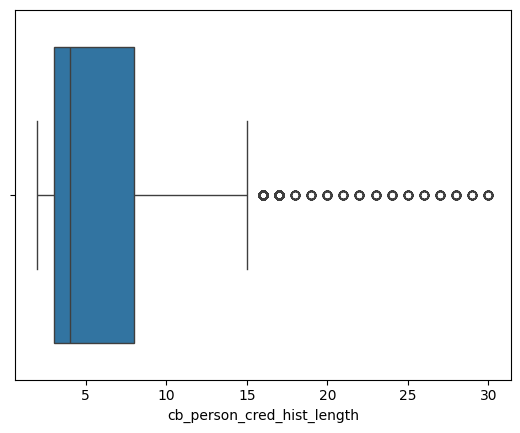

In [66]:
import matplotlib.pyplot as plt
for i in num_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [67]:
(df['person_age']>100).sum()

np.int64(5)

In [68]:
(df['person_emp_length']>60).sum()

np.int64(2)

<Axes: >

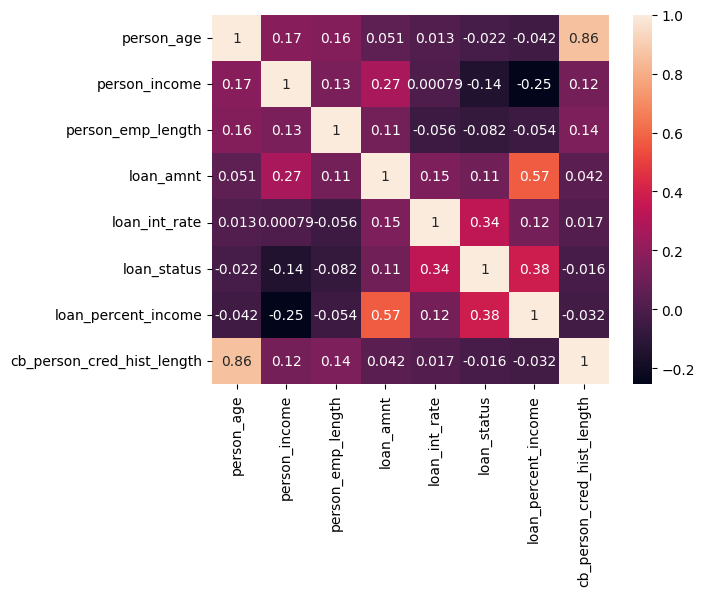

In [69]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [70]:
df_copy = df.copy()

In [71]:
original_shape = df_copy.shape
print(original_shape)
df_copy.drop_duplicates(inplace=True)
print(df_copy.shape)



(32581, 12)
(32416, 12)


In [72]:
df_copy = df_copy[df_copy['person_age']<=100]
df_copy = df_copy[df_copy['person_age']>=18]

In [73]:
df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]

In [74]:
df_copy = df_copy[df_copy['loan_amnt']> 0]

### Splitting

In [75]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [76]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

### Handle Class Imbalance

In [77]:
import numpy as np
neg,pos = np.bincount(y_train)
scale_weights = neg/pos
print(scale_weights)

3.6312213039485766


### Pipeline and Columns transformer

In [78]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='mean')),
            ('scaler',StandardScaler())
        ]),num_cols),

        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
            ('onehot',OneHotEncoder())
        ]),cat_cols)
    ]
)

In [79]:
preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='mean')),
        ]),num_cols),

        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value='Missing')),
            ('onehot',OneHotEncoder())
        ]),cat_cols)
    ]
)

### Evaluation function

In [80]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,precision_recall_curve,confusion_matrix,classification_report

In [130]:
def evaluate(model_name,model,X_test,y_test,threshold=None):
  y_pred = model.predict(X_test)
  y_pred_proba = model.predict_proba(X_test)[:,1]

  acc = accuracy_score(y_test,y_pred)
  prec = precision_score(y_test,y_pred)
  rec = recall_score(y_test,y_pred)
  f1 = f1_score(y_test,y_pred)

  cm = confusion_matrix(y_test,y_pred)
  class_report = classification_report(y_test,y_pred)

  print(model_name)
  print(f"Accuracy: {acc}")
  print(f"Precision: {prec}")
  print(f"Recall: {rec}")
  print(f"F1: {f1}")
  print('---------------------------')
  print('Classification Report')
  print(class_report)
  print('---------------------------')
  print('Confusion Matrix')
  sns.heatmap(cm,annot=True,fmt='g')
  plt.show()

  precisions,recalls,threshold = precision_recall_curve(y_test,y_pred_proba)
  plt.plot(recalls,precisions)
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.title(f'{model_name} Precision Recall Curve')
  plt.show()




### Stratified Cross Validation

In [82]:
from sklearn.model_selection import StratifiedKFold,cross_validate
skf = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}

In [83]:
from sklearn.linear_model import LogisticRegression

lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder())]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [84]:
from xgboost import XGBClassifier

xg_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimator=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weights, random_state=42))
])



In [85]:
xg_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [86]:
for cv_name,pipe in [('Logistic Regression',lr_cv_pipeline),('XGBoost',xg_cv_pipeline)]:
  cv_results=cross_validate(pipe,X_train,y_train,cv=skf,scoring=scoring,n_jobs=-1)
  print(cv_name)
  print(f"ROC-AUC: {cv_results['test_roc_auc'].mean()}")
  print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
  print(f"Precision: {cv_results['test_precision'].mean()}")
  print(f"Recall: {cv_results['test_recall'].mean()}")
  print(f"F1: {cv_results['test_f1'].mean()}")
  print("------------------------------------------------")

Logistic Regression
ROC-AUC: 0.8705017162553327
Accuracy: 0.8116346210849974
Precision: 0.544857346045846
Recall: 0.7785123966942149
F1: 0.6409531225245716
------------------------------------------------
XGBoost
ROC-AUC: 0.9393017290490974
Accuracy: 0.9082758223764131
Precision: 0.7899412913957627
Recall: 0.785307621671258
F1: 0.7872112130669427
------------------------------------------------


### Baseline model

In [87]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder())]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

Baseline Model
Accuracy: 0.8193497224425059
Precision: 0.5580426861009891
Recall: 0.7870778267254038
F1: 0.6530612244897959
---------------------------
Classification Report
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305

---------------------------
Confusion Matrix


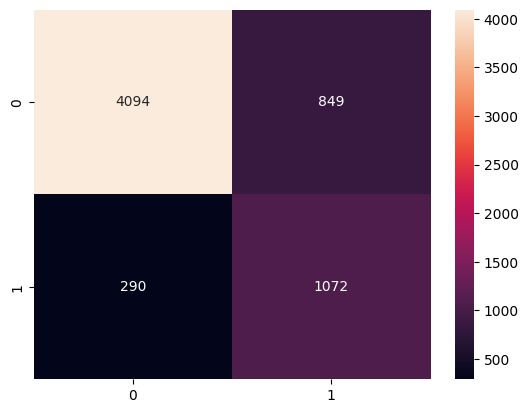

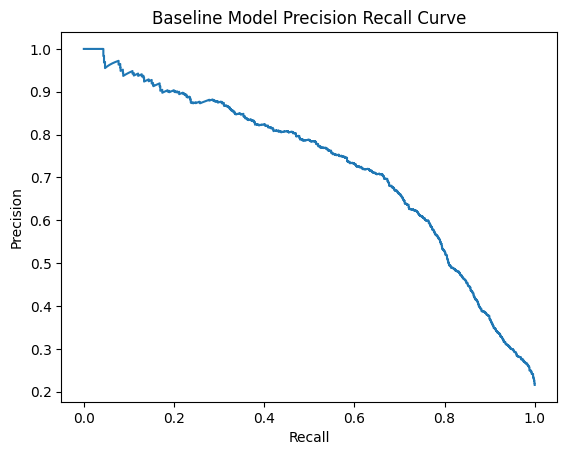

In [88]:
# Evaluate model
evaluate('Baseline Model',baseline_model,X_test,y_test)

### XGboost model


In [89]:
xgboost_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(n_estimator=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weights, random_state=42))

])
xgboost_model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:40:50] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

XGBoost Model
Accuracy: 0.906740681998414
Precision: 0.7784172661870503
Recall: 0.7944199706314243
F1: 0.7863372093023255
---------------------------
Classification Report
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4943
           1       0.78      0.79      0.79      1362

    accuracy                           0.91      6305
   macro avg       0.86      0.87      0.86      6305
weighted avg       0.91      0.91      0.91      6305

---------------------------
Confusion Matrix


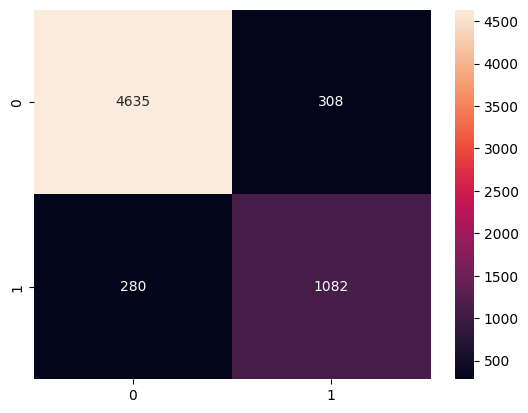

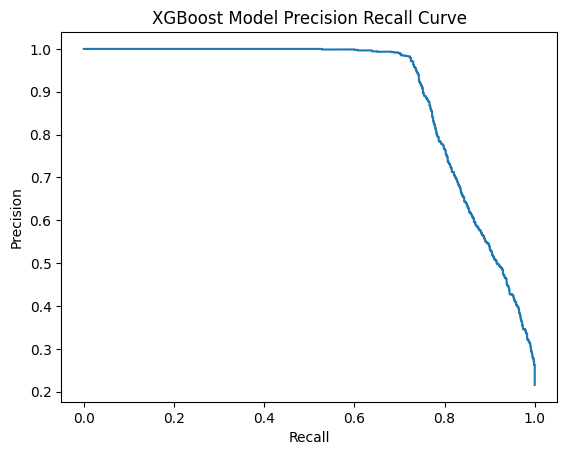

In [90]:
### Evaluate model
evaluate('XGBoost Model',xgboost_model,X_test,y_test)

XGBoost
Accuracy: 0.906740681998414
Precision: 0.7784172661870503
Recall: 0.7944199706314243
F1: 0.7863372093023255
---------------------------
Classification Report
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4943
           1       0.78      0.79      0.79      1362

    accuracy                           0.91      6305
   macro avg       0.86      0.87      0.86      6305
weighted avg       0.91      0.91      0.91      6305

---------------------------
Confusion Matrix


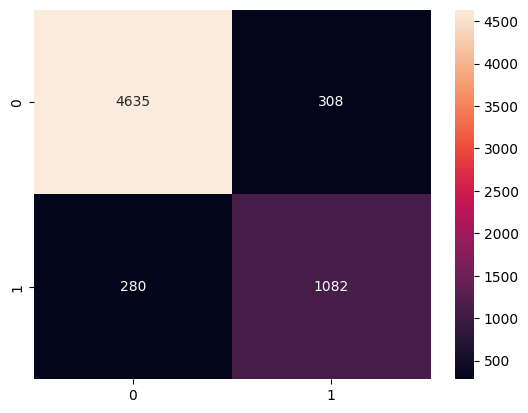

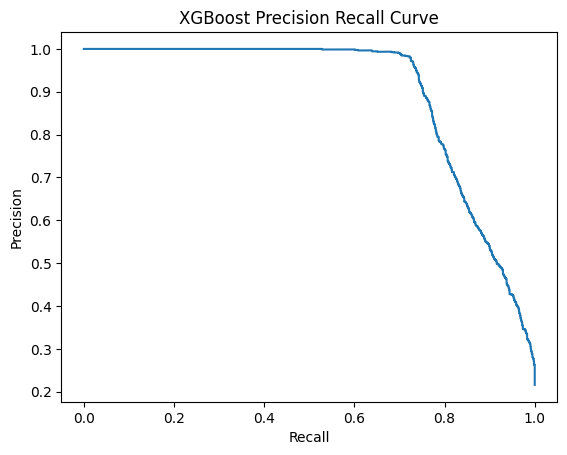

In [131]:
prob = xgboost_model.predict_proba(X_test)[:, 1]

#For each threshold calculate Precision and Recall
precisions, recalls , thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions-recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold.
evaluate("XGBoost", xgboost_model, X_test, y_test, best_threshold)

### XGBoost Hyperparameter tuning

In [91]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint,uniform
param_grids={
    'classifier__n_estimators':randint(150,600),
    'classifier__max_depth':randint(3,19),
    'classifier__learning_rate':uniform(0.01,0.5),
    'classifier__colsample_bytree':uniform(0.6,0.4), #col sampling
    'classifier__subsample':uniform(0.6,0.4), #rows sampling
    'classifier__min_child_weight':randint(1,10),
    'classifier__gamma':uniform(0,5)}
#lower gamma -> more splits -> complex tree -> overfitting risks
#higher gamma -> less splits -> simpler tree -> low overfitting

In [92]:
random_search = RandomizedSearchCV(xgboost_model,param_grids,n_iter=150,cv=skf,scoring='average_precision',n_jobs=-1,verbose=1)

In [93]:
random_search

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeli...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79630cc17c50>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7963638108d0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79630cce2210>},
                   scoring='average_precision', verbose=1)

In [94]:
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:53:18] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeli...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79630cc17c50>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7963638108d0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79630cce2210>},
                   scoring='average_precision', verbose=1)

In [95]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.7737465617600263),
 'classifier__gamma': np.float64(1.6739739827489193),
 'classifier__learning_rate': np.float64(0.08033151489421712),
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 4,
 'classifier__n_estimators': 451,
 'classifier__subsample': np.float64(0.9101367652534575)}

XGBoost Tuned Model
Accuracy: 0.9205392545598731
Precision: 0.8219895287958116
Recall: 0.8069016152716594
F1: 0.8143756947017414
---------------------------
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305

---------------------------
Confusion Matrix


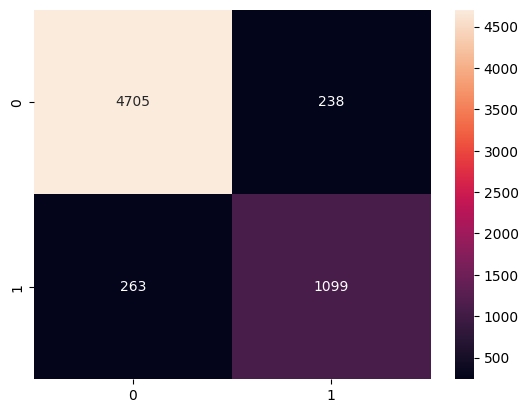

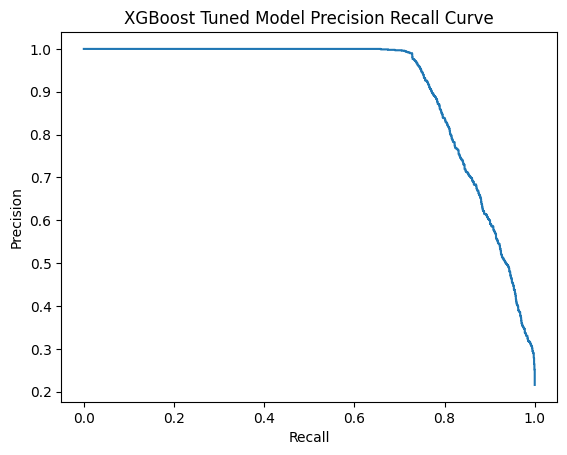

In [96]:
evaluate('XGBoost Tuned Model',random_search,X_test,y_test)

### Calibration

In [112]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(best_model, method='sigmoid', cv=5)
calibrated_model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:55:33] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:55:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:55:41] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:55:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [18:55

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(fill_value='Miss...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.08033151489421712),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=5,
                                                                max_leaves=None,
                                                                min_child_weight=4,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimator=300,
                                                                n_estimators=451,
                                                                n_jobs=None, ...))]))

In [113]:
ucalibrated = xgboost_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [114]:
actual_uncal, predicted_uncal = calibration_curve(y_test, ucalibrated, n_bins=10)
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

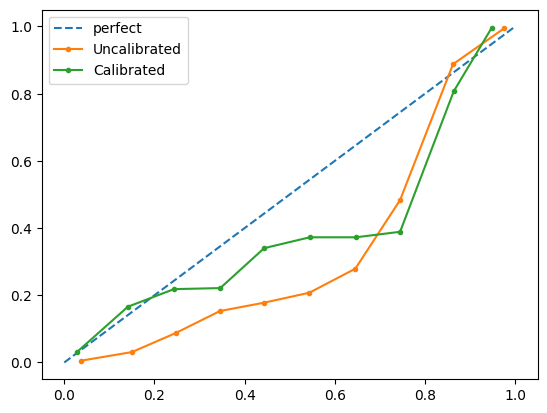

In [115]:
plt.plot([0,1],[0,1],linestyle='--',label='perfect')
plt.plot(predicted_uncal, actual_uncal, marker=".", label='Uncalibrated')
plt.plot(predicted_cal, actual_cal, marker='.', label='Calibrated')
plt.legend()
plt.show()

### Shap Interpretation

In [116]:
import shap

In [117]:
xgb_classifier = xgboost_model.named_steps['classifier']
X_test_transformed = xgboost_model.named_steps['preprocessor'].transform(X_test)

In [118]:
features_names = xgboost_model.named_steps['preprocessor'].get_feature_names_out()

In [119]:
X_test_df = pd.DataFrame(X_test_transformed,columns=features_names)

In [120]:
explainer = shap.TreeExplainer(xgb_classifier)

In [121]:
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-2.3433661e-02,  7.9883665e-02,  1.3316482e-01, ...,
        -6.4050169e-03, -1.0318534e-02,  0.0000000e+00],
       [ 4.1914470e-02, -7.7279031e-01, -3.9584033e-02, ...,
        -8.0150450e-03,  1.1843910e-03,  0.0000000e+00],
       [ 5.6404125e-02,  3.3753865e+00,  1.4458810e-01, ...,
        -6.4722248e-03, -1.8982838e-03,  0.0000000e+00],
       ...,
       [-5.7305801e-03,  4.3736851e-01,  1.4971987e-02, ...,
        -7.6910476e-03, -1.0317841e-02,  0.0000000e+00],
       [-1.0381866e-03, -6.8226683e-01,  1.6826335e-02, ...,
        -8.2323961e-03, -1.0243836e-02,  0.0000000e+00],
       [-1.0034970e-01, -4.0515509e-01,  6.2988661e-02, ...,
        -7.4921921e-03, -1.0509256e-02,  0.0000000e+00]], dtype=float32)

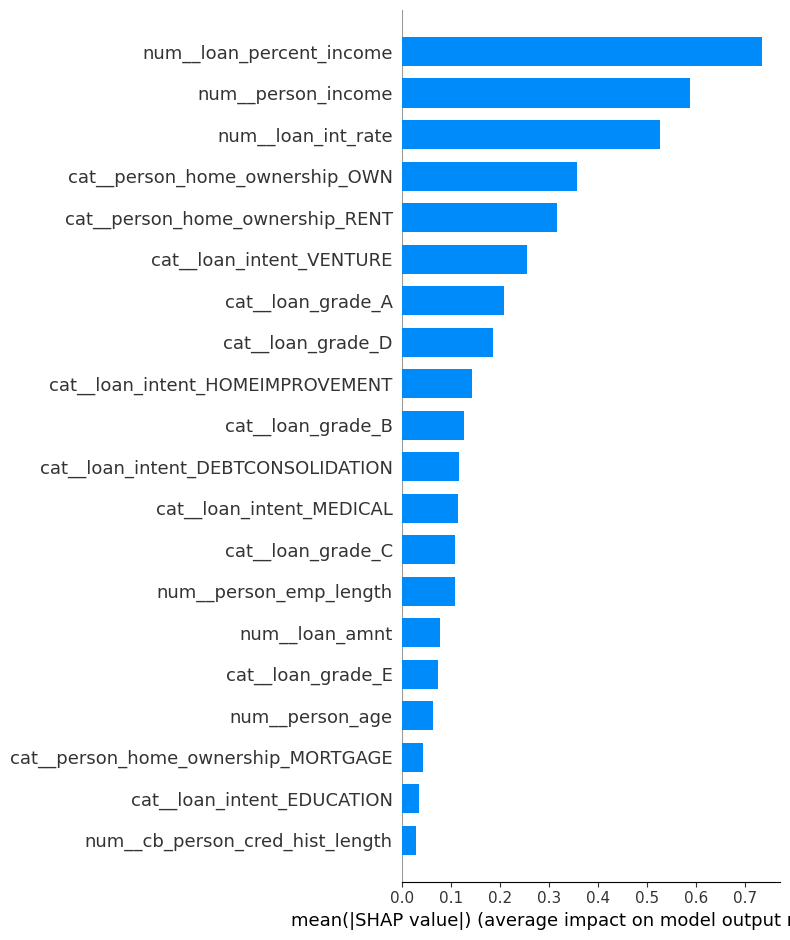

In [122]:
shap.summary_plot(shap_values, X_test_df, plot_type="bar")

### Analyzing False positive and False negatives

In [123]:
y_pred = random_search.predict(X_test)

In [124]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred
result_df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0


In [125]:
false_positives = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
false_negatives = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]
print("False Positives:")
print(len(false_positives))
print("\nFalse Negatives:")
print(len(false_negatives))

False Positives:
238

False Negatives:
263


### Saving the model

In [126]:
import joblib
joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

calibrated model
Accuracy: 0.9335448057097542
Precision: 0.9117903930131004
Recall: 0.7665198237885462
F1: 0.8328679696848823
---------------------------
Classification Report
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      4943
           1       0.91      0.77      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.93      0.87      0.90      6305
weighted avg       0.93      0.93      0.93      6305

---------------------------
Confusion Matrix


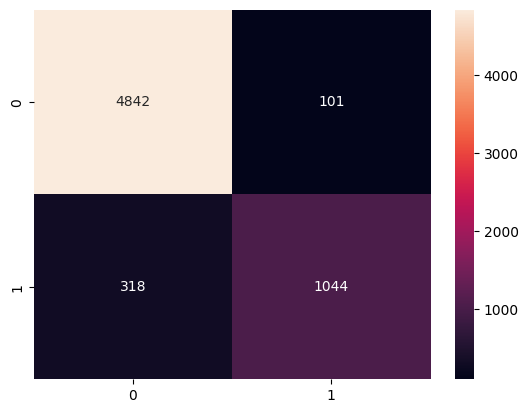

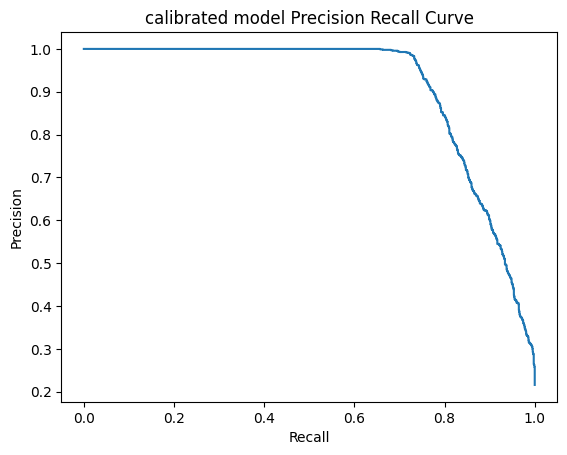

In [138]:
prob = calibrated_model.predict_proba(X_test)[:, 1]

precisions, recalls , thresholds = precision_recall_curve(y_test, prob)

f1 = 2 * (precisions-recalls) / (precisions + recalls + 1e-9)

best = np.argmax(f1[:-1])
calibrated_threshold = thresholds[best]

evaluate("calibrated model", calibrated_model, X_test, y_test, calibrated_threshold)

In [139]:
calibrated_threshold

np.float64(0.9544046958360465)

In [140]:
joblib.dump(calibrated_threshold,"calibrated_threshold.pkl")

['calibrated_threshold.pkl']